# Bayesian augmented synthetic control

This how-to fits two known panels with `AugmentedSyntheticControl`. One PyMC model draws simplex base weights and one shared donor prognostic correction. The plotted bands are posterior uncertainty for that joint model. They do not claim nominal coverage.

The model note is [Augmented synthetic control](../knowledgebase/augmented-synthetic-control.md).


## Model specification

On a wide panel, time is the index and `treatment_time` is the first post-period row. For treated unit $u$ and post-period time $t$ the counterfactual is

$$
\text{donor\_post}[t] \cdot w_u + (X_u - X_{\text{donors}} w_u) \cdot \beta[t].
$$

$w_u$ is a Dirichlet draw on the donors. $X_u$ and each donor row of $X_{\text{donors}}$ are full pre-period outcome vectors. $\beta[t]$ is the prognostic coefficient vector at time $t$, with a $\mathrm{Normal}(0, \tau)$ prior and $\tau \sim \mathrm{HalfNormal}(1)$. Both Normal likelihoods use observation scale 1. Treated post-period outcomes do not enter either likelihood or the counterfactual.

`treatment_effect` is the treated post-period outcome minus that counterfactual.

The public class is imported from the experiment module, not from the package root. `fit` forwards `sample_kwargs` to `pymc.sample` and stores the joint posterior on `idata`. The names used below are `base_weights`, `prognostic_coefficients`, `counterfactual`, `treatment_effect`, and `tau`.


In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from causalpy.experiments.augmented_synthetic_control import (
    AugmentedSyntheticControl,
)

SAMPLE = {
    "draws": 80,
    "tune": 80,
    "chains": 1,
    "random_seed": 11,
    "progressbar": False,
    "compute_convergence_checks": False,
}


def donor_frame(scale=5.0):
    times = np.arange(8)
    donors = pd.DataFrame(
        {
            "c0": scale * np.array([1.0, 2, 1, 2, 1, 2, 1, 2]),
            "c1": scale * np.array([2.0, 1, 2, 1, 2, 1, 2, 1]),
            "c2": scale * np.array([0.0, 0, 3, 1, 0, 0, 3, 1]),
        },
        index=times,
    )
    return donors


def fit_panel(treated, donors):
    data = donors.copy()
    data["treated"] = treated
    experiment = AugmentedSyntheticControl(
        data,
        treatment_time=4,
        control_units=["c0", "c1", "c2"],
        treated_units=["treated"],
    )
    return experiment.fit(SAMPLE)


def posterior_mean(idata, name):
    return idata.posterior[name].mean(("chain", "draw"))


def show_figure(figure):
    figure.tight_layout()
    return figure

## In-hull panel

The treated pre-period is the convex combination $(1/2, 1/4, 1/4)$ of the donors. The post-period adds a planted shift of 8. That shift is not used to fit weights or prognostic coefficients.


In [2]:
donors = donor_frame()
planted_weights = np.array([0.5, 0.25, 0.25])
untreated = donors.to_numpy() @ planted_weights
treated = untreated.copy()
treated[4:] += 8.0
success = fit_panel(treated, donors)
idata = success.idata
print(sorted(idata.posterior.data_vars))

['base_weights', 'counterfactual', 'prognostic_coefficients', 'tau', 'treatment_effect']


## Plots of the frozen quantities

The first figure is the post-period counterfactual against the observed treated series and the planted untreated path. The band is the posterior of `counterfactual`. It is not a nominal coverage interval.


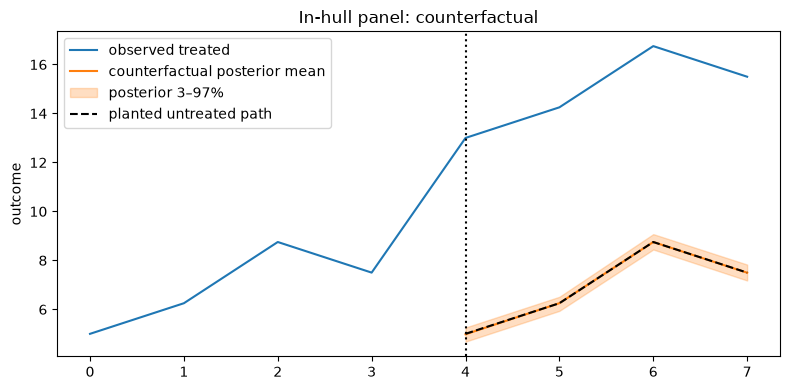

In [3]:
post_time = donors.index[donors.index >= 4]
cf = idata.posterior["counterfactual"].sel(treated_units="treated")
cf_mean = cf.mean(("chain", "draw"))
cf_low = cf.quantile(0.03, dim=("chain", "draw"))
cf_high = cf.quantile(0.97, dim=("chain", "draw"))

figure, axis = plt.subplots(figsize=(8, 4))
axis.plot(donors.index, treated, color="C0", label="observed treated")
axis.plot(post_time, cf_mean, color="C1", label="counterfactual posterior mean")
axis.fill_between(
    post_time, cf_low, cf_high, color="C1", alpha=0.25, label="posterior 3–97%"
)
axis.plot(
    post_time,
    untreated[4:],
    color="black",
    linestyle="--",
    label="planted untreated path",
)
axis.axvline(4, color="black", linestyle=":")
axis.set_ylabel("outcome")
axis.set_title("In-hull panel: counterfactual")
axis.legend()
show_figure(figure)

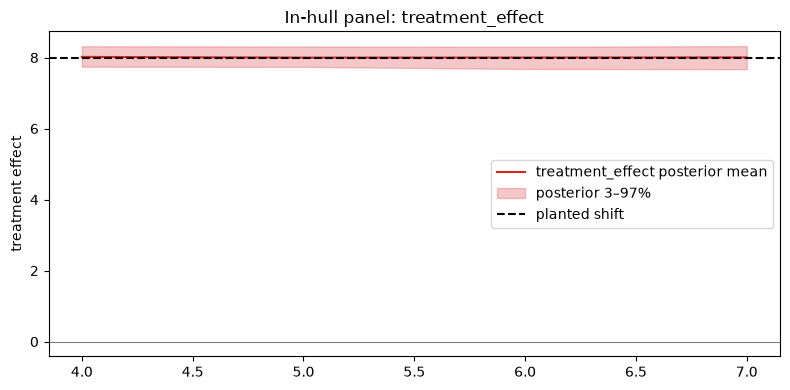

In [4]:
effect = idata.posterior["treatment_effect"].sel(treated_units="treated")
effect_mean = effect.mean(("chain", "draw"))
effect_low = effect.quantile(0.03, dim=("chain", "draw"))
effect_high = effect.quantile(0.97, dim=("chain", "draw"))

figure, axis = plt.subplots(figsize=(8, 4))
axis.plot(post_time, effect_mean, color="C3", label="treatment_effect posterior mean")
axis.fill_between(
    post_time, effect_low, effect_high, color="C3", alpha=0.25, label="posterior 3–97%"
)
axis.axhline(8.0, color="black", linestyle="--", label="planted shift")
axis.axhline(0.0, color="gray", linewidth=0.8)
axis.set_ylabel("treatment effect")
axis.set_title("In-hull panel: treatment_effect")
axis.legend()
show_figure(figure)

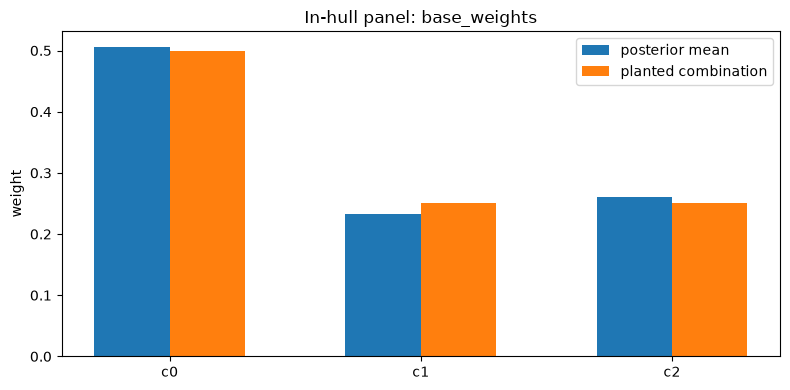

In [5]:
weights = posterior_mean(idata, "base_weights").sel(treated_units="treated")
figure, axis = plt.subplots(figsize=(8, 4))
positions = np.arange(len(weights))
axis.bar(positions - 0.15, weights.values, width=0.3, label="posterior mean")
axis.bar(positions + 0.15, planted_weights, width=0.3, label="planted combination")
axis.set_xticks(positions, list(weights.control_units.values))
axis.set_ylabel("weight")
axis.set_title("In-hull panel: base_weights")
axis.legend()
show_figure(figure)

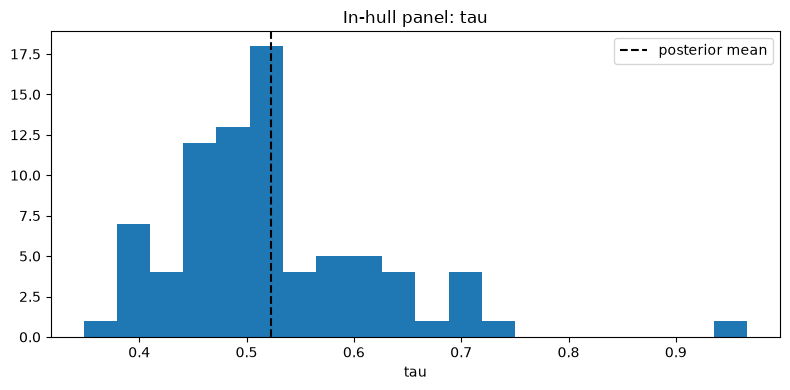

In [6]:
tau = idata.posterior["tau"]
figure, axis = plt.subplots(figsize=(8, 4))
axis.hist(tau.values.ravel(), bins=20, color="C0")
axis.axvline(float(tau.mean()), color="black", linestyle="--", label="posterior mean")
axis.set_xlabel("tau")
axis.set_title("In-hull panel: tau")
axis.legend()
show_figure(figure)

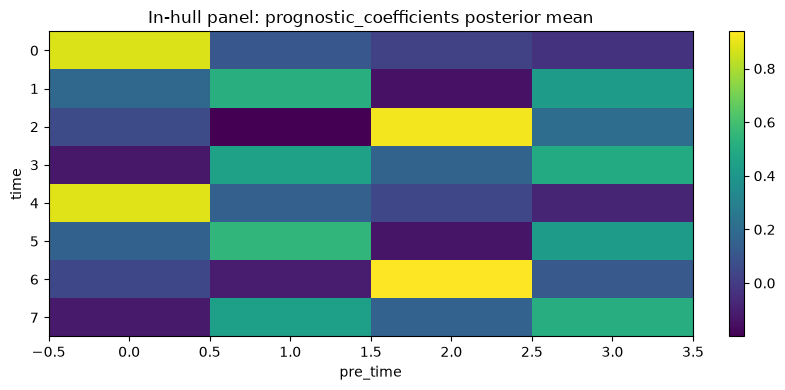

In [7]:
beta = posterior_mean(idata, "prognostic_coefficients")
figure, axis = plt.subplots(figsize=(8, 4))
image = axis.imshow(beta.values, aspect="auto")
axis.set_xlabel("pre_time")
axis.set_ylabel("time")
axis.set_title("In-hull panel: prognostic_coefficients posterior mean")
figure.colorbar(image, ax=axis, fraction=0.046)
show_figure(figure)

## Successful case

The treated pre-period lies in the convex hull, so simplex weights can approach the planted combination. The pre-period residual below is the gap that remains after that weighted donor path. It is small relative to the donor scale, not zero: the weight likelihood has a fixed observation scale of 1, and the plotted mean is one posterior summary.

The posterior mean of `treatment_effect` sits near the planted shift of 8 on this panel. That is a description of this fit. It is not a claim that the band has nominal coverage.


In [8]:
weight_mean = posterior_mean(idata, "base_weights").sel(treated_units="treated").values
pre_fit = donors.to_numpy()[:4] @ weight_mean
pre_residual = treated[:4] - pre_fit
effect_mean_values = (
    posterior_mean(idata, "treatment_effect").sel(treated_units="treated").values
)
print("posterior mean base_weights", weight_mean)
print("pre-period residual", pre_residual)
print("posterior mean treatment_effect", effect_mean_values)

posterior mean base_weights [0.50608724 0.2332186  0.26069415]
pre-period residual [ 0.13737774  0.02303454 -0.02303454 -0.03043622]
posterior mean treatment_effect [8.01791469 7.9977907  8.00012208 8.00381751]


## Difficult case

The treated series is the constant 40. That pre-period sits outside the convex hull of the donors, so no simplex weight vector can match it. The pre-intervention fit stays imperfect. The prognostic correction can still move the post-period counterfactual, because that term uses the pre-period imbalance and coefficients learned from donors only. A posterior mean that moves toward 40 on this panel is still only uncertainty in the recorded model. It does not claim nominal coverage.


In [9]:
difficult_treated = np.full(donors.shape[0], 40.0)
difficult = fit_panel(difficult_treated, donors)
difficult_idata = difficult.idata
difficult_weights = (
    posterior_mean(difficult_idata, "base_weights").sel(treated_units="treated").values
)
difficult_pre_fit = donors.to_numpy()[:4] @ difficult_weights
difficult_residual = difficult_treated[:4] - difficult_pre_fit
print("posterior mean base_weights", difficult_weights)
print("pre-period residual", difficult_residual)
print(
    "posterior mean counterfactual",
    posterior_mean(difficult_idata, "counterfactual")
    .sel(treated_units="treated")
    .values,
)
print(
    "posterior mean treatment_effect",
    posterior_mean(difficult_idata, "treatment_effect")
    .sel(treated_units="treated")
    .values,
)

posterior mean base_weights [0.50050141 0.49641225 0.00308634]
pre-period residual [32.53337048 32.51292465 32.48707535 32.49749294]
posterior mean counterfactual [39.4482385  39.5463419  39.90158331 39.55659468]
posterior mean treatment_effect [0.5517615  0.4536581  0.09841669 0.44340532]


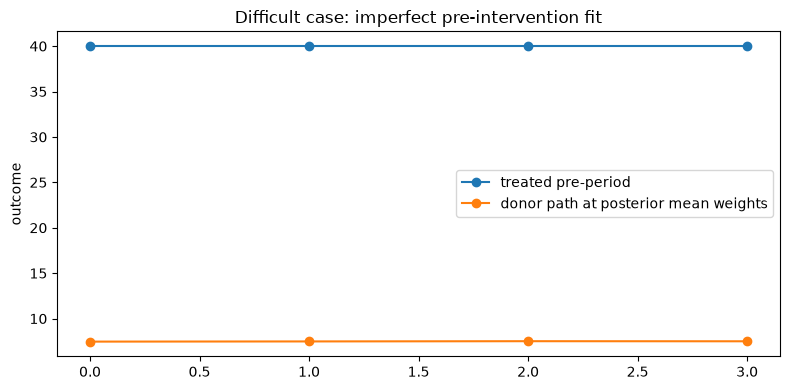

In [10]:
figure, axis = plt.subplots(figsize=(8, 4))
axis.plot(
    donors.index[:4],
    difficult_treated[:4],
    color="C0",
    marker="o",
    label="treated pre-period",
)
axis.plot(
    donors.index[:4],
    difficult_pre_fit,
    color="C1",
    marker="o",
    label="donor path at posterior mean weights",
)
axis.set_ylabel("outcome")
axis.set_title("Difficult case: imperfect pre-intervention fit")
axis.legend()
show_figure(figure)

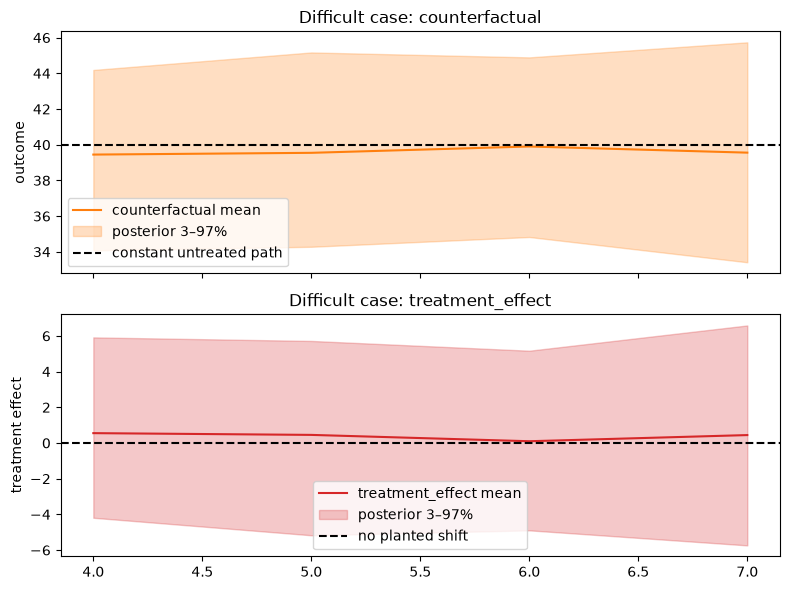

In [11]:
difficult_cf = difficult_idata.posterior["counterfactual"].sel(treated_units="treated")
difficult_effect = difficult_idata.posterior["treatment_effect"].sel(
    treated_units="treated"
)
figure, axes = plt.subplots(2, 1, figsize=(8, 6), sharex=True)
axes[0].plot(
    post_time,
    difficult_cf.mean(("chain", "draw")),
    color="C1",
    label="counterfactual mean",
)
axes[0].fill_between(
    post_time,
    difficult_cf.quantile(0.03, dim=("chain", "draw")),
    difficult_cf.quantile(0.97, dim=("chain", "draw")),
    color="C1",
    alpha=0.25,
    label="posterior 3–97%",
)
axes[0].axhline(40.0, color="black", linestyle="--", label="constant untreated path")
axes[0].set_ylabel("outcome")
axes[0].set_title("Difficult case: counterfactual")
axes[0].legend()
axes[1].plot(
    post_time,
    difficult_effect.mean(("chain", "draw")),
    color="C3",
    label="treatment_effect mean",
)
axes[1].fill_between(
    post_time,
    difficult_effect.quantile(0.03, dim=("chain", "draw")),
    difficult_effect.quantile(0.97, dim=("chain", "draw")),
    color="C3",
    alpha=0.25,
    label="posterior 3–97%",
)
axes[1].axhline(0.0, color="black", linestyle="--", label="no planted shift")
axes[1].set_ylabel("treatment effect")
axes[1].set_title("Difficult case: treatment_effect")
axes[1].legend()
show_figure(figure)

## What the posterior does not say

Treated post-period outcomes are subtracted when `treatment_effect` is formed. They do not enter `counterfactual`. Shifting those outcomes and refitting with the same seed leaves the counterfactual draws unchanged and moves the treatment effect by the same shift.

The bands above include uncertainty from the Dirichlet weights, from `tau`, and from the two Normal likelihoods with observation scale 1. They exclude the treated post-period from both likelihoods. They do not claim nominal coverage.


In [12]:
shifted = treated.copy()
shifted[4:] += 4.0
refit = fit_panel(shifted, donors)
same_counterfactual = np.allclose(
    idata.posterior["counterfactual"].values,
    refit.idata.posterior["counterfactual"].values,
)
effect_shift = (
    refit.idata.posterior["treatment_effect"].values
    - idata.posterior["treatment_effect"].values
)
print("counterfactual unchanged:", same_counterfactual)
print("treatment_effect moved by 4:", np.allclose(effect_shift, 4.0))

counterfactual unchanged: True
treatment_effect moved by 4: True
